<a href="https://colab.research.google.com/github/ElBaron-27/UACJ_Ruben/blob/main/Actividad_EDA_predictivo_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Ruben Alejandro Uribe Rodriguez

**Matrícula:** 271774

**Fecha:** 13 de octubre del 2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? |Cliente |
| ¿Qué se predice? | y: yes si el cliente contrató el depósito, no si no |
| ¿Qué tipo de problema es? | Clasificación binaria |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Antes de que se llame al cliente y tendríamos la información demografica del cliente, datos de campañas anteriores e información macroeconómica|
| ¿Qué columnas no deberían usarse como características y por qué? | Duración ya que esa información no la tendríamos disponible antes de llamar al cliente |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Escribe tu respuesta aquí, antes de ejecutar la celda de código. **Un 20%**

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código. **Respuesta: Considero que si habrá valores unknown debido a la magnitud del dataset y pienso que seguramente en las variables categoricas, principalmente en edad, estado civil y empleo. Por el tamaño del dataset, considero que de las 41,188 filas probablemente en unas 5 mil veamos unknown.**

In [2]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.
print("Filas y columnas:", df.shape)
df.info()
df.nunique().sort_values()

Filas y columnas: (41188, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  c

,0
contact,2
y,2
default,3
loan,3
poutcome,3
housing,3
marital,4
day_of_week,5
previous,8
education,8


In [3]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

print("Valores faltantes (NaN) en todo el conjunto:", df.isna().sum().sum())

# Obtener el conteo de 'unknown' por columna categórica
unknown_counts = (df[categoricas] == "unknown").sum()

# Filtrar solo aquellas columnas que tengan al menos un 'unknown'
unknown_counts = unknown_counts[unknown_counts > 0]

# Crear un DataFrame para mostrar el conteo y el porcentaje
unknown_df = pd.DataFrame({
    'Conteo': unknown_counts,
    'Porcentaje (%)': (unknown_counts / len(df)) * 100
})

print("\nFilas con 'unknown' en columnas categóricas:")
print(unknown_df)

Valores faltantes (NaN) en todo el conjunto: 0

Filas con 'unknown' en columnas categóricas:
           Conteo  Porcentaje (%)
job           330        0.801204
marital        80        0.194231
education    1731        4.202680
default      8597       20.872584
housing       990        2.403613
loan          990        2.403613


In [4]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
print("filas repetidos:", df.duplicated().sum())


filas repetidos: 12


In [5]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,

# filas con pdays
filas_pdays = (df["pdays"] == 999).sum()

# porcentaje
porcentaje_pdays = (filas_pdays / len(df)) * 100

print("Filas con pdays igual a 999:", filas_pdays)
print("Porcentaje de filas con pdays igual a 999:", porcentaje_pdays)


#  - una tabla de contingencia entre poutcome y (previous == 0),
print("\nTabla de contingencia entre poutcome y (previous == 0):")
print(pd.crosstab(df["poutcome"], df["previous"] == 0))


#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.
print("\nTabla de contingencia entre poutcome y (pdays == 999):")
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))

Filas con pdays igual a 999: 39673
Porcentaje de filas con pdays igual a 999: 96.32174419733903

Tabla de contingencia entre poutcome y (previous == 0):
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Tabla de contingencia entre poutcome y (pdays == 999):
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [6]:
# B5. Rangos según el dominio. Escribe el código que muestre:

#  - la edad mínima y máxima,

print("Edad mínima:", df["age"].min())
print("Edad máxima:", df["age"].max())

#  - la duración mínima y máxima,
print("Duración mínima:", df["duration"].min())
print("Duración máxima:", df["duration"].max())


#  - cuántas llamadas tienen duration igual a 0,

print("Duración igual a cero:", (df["duration"] == 0).sum())

#  - el mínimo y el máximo de campaign,

print("Campaign mínima:", df["campaign"].min())
print("Campaign máxima:", df["campaign"].max())


#  - cuántas filas tienen previous negativo.

print("Previous negativo:", (df["previous"] < 0).sum())

Edad mínima: 17
Edad máxima: 98
Duración mínima: 0
Duración máxima: 4918
Duración igual a cero: 4
Campaign mínima: 1
Campaign máxima: 56
Previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Problemas encontrados:**
1. Default tiene una cantidad importante de *Unknown* siendo 8597 que representa el 20.87%.
2. Hay 12 filas repetidas (exactamente iguales)
3. Posibles outliers aunque sin confirmar, ya que se encontró a alguien con 98 años (si estamos vendiendo depósitos a plazo, sería muy raro que alguien con esa edad haga la contratación aunque no sería imposible). Otro posible outlier son los 56 contactos que se tuvieron con un cliente, por lo que si estamos vendiendo un producto es excesivo ese número de contactos.
**Dependen del significado:** El de pdays:999 ya que podría confundirse, y sólo se conoce el significado leyendo la documentación
**Frente a mi predicción:** No le atiné. Predije aproximadamente 5 mil unknown pero fueron un poco mas (Casi 8600) asimismo yo creía que los valores demograficos iban a tener mayor unknown ya que en ocasiones las personas no quieren dar esa información, por lo que me sorprendió que no tengan registrado si tienen credito en incumplimiento, lo cual me hace pensar que es una respuesta que obtienen de los clientes y que estos no quieren contestar

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

**No eliminaría las filas ya que se perdería una cantidad importante de datos. Tampoco tengo elementos para decidir si quiere decir que están o no en incumplimiento o si fue porque no quisieron contestar. Yo la conservaría así, quizá en algún punto haciendo el análisis del resto de los datos, se pueda inferir el por qué hay tanto unknown.**

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código. **Mi predicción es que si debería ser igual ya que la cantidad de registros para ambas partes es lo suficientemente representativa, además de que el dataset, fuera de la columna de default los unknown, los demas datos parecen ser uniformes.**

In [7]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.

entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)

ent = entrenamiento.copy()
ent["suscribe"] = (ent["y"] == "yes").astype(int)

# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.
print("Entrenamiento:", entrenamiento.shape, "| Prueba:", prueba.shape)
print("Porcentaje de contratación en entrenamiento:", round((entrenamiento["y"] == "yes").mean() * 100, 2), "%")
print("Porcentaje de contratación en prueba:", round((prueba["y"] == "yes").mean() * 100, 2), "%")

Entrenamiento: (32950, 21) | Prueba: (8238, 21)
Porcentaje de contratación en entrenamiento: 11.27 %
Porcentaje de contratación en prueba: 11.26 %


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [8]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.  **Efectivamente el porcentaje de contratación tanto en entrenamiento como en prueba fueron casi similares, por lo que puedo decir que mi predicción fue acertada**

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.**Considero que sería una exactitud alta ya que sería el porcentaje de los que no contrataron, alrededor de un 80%**

     clientes  porcentaje
y                        
no      29238        88.7
yes      3712        11.3

Razón entre clases (mayoritaria / minoritaria): 7.88
Exactitud de responder siempre No: 88.7 %


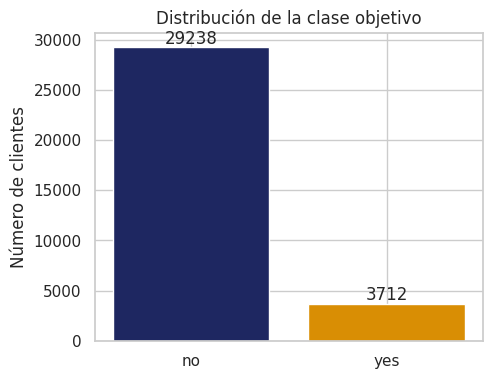

In [9]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.

ent["suscribe"] = (ent["y"] == "yes").astype(int)

conteo = ent["y"].value_counts()
porcentaje = (ent["y"].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"clientes": conteo, "porcentaje": porcentaje}))
print()
print("Razón entre clases (mayoritaria / minoritaria):", round(conteo["no"] / conteo["yes"], 2))
print("Exactitud de responder siempre No:", round((1 - ent["suscribe"].mean()) * 100, 1), "%")

fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(conteo.index, conteo.values, color=conteo.index.map(COLORES_CLASE))
ax.bar_label(barras)
ax.set_title("Distribución de la clase objetivo")
ax.set_ylabel("Número de clientes")
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción. **En mi predicción yo estimaba un 20% de contratación y 80% de no-contratación, lo cual si bien acierta en cuanto a que el porcentaje es alto, los resultado han demostrado valores cercanos al 90% en no-contratación. Esto implica que la exactitud no es una métrica adecuada por sí sola, sólo se podría tomar como línea base y despues podríamos evaluar con otras métricas**

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.**Principalmente la duración de la llamada, ya que cuando nos venden por teléfono y no nos interesa, solemos cortar al operador en el primer minuto mientras que cuando nos interesa hacemos preguntas y cuando contratamos suele ser un proceso largo al teléfono, por lo que yo espero ver valores muy disparesd**

      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1


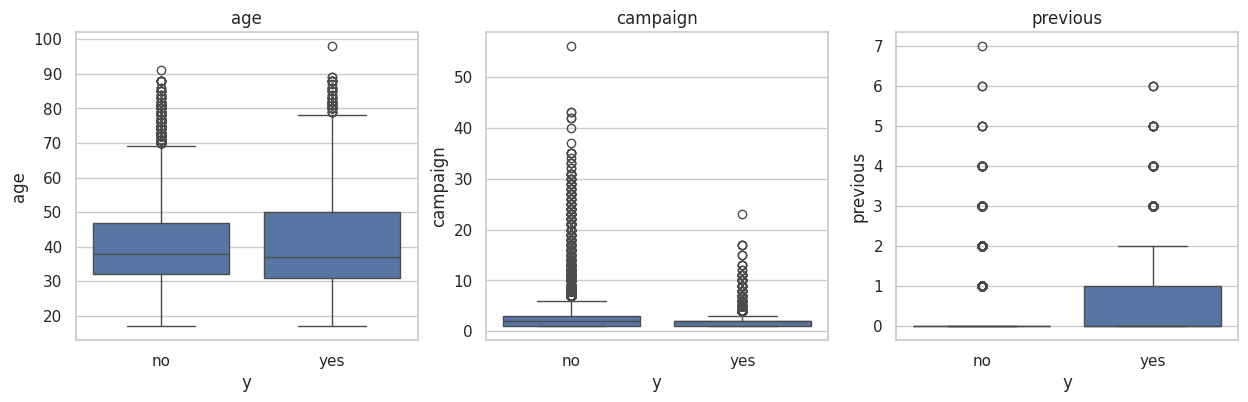

In [10]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,

numericas_mediana = ent.groupby("y")[numericas].median()
print(numericas_mediana)

#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.

vars_caja = ["age", "campaign", "previous"]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, variable in zip(ejes, vars_caja):
    sns.boxplot(data=entrenamiento, x="y", y=variable, ax=eje)
    eje.set_title(variable)
plt.show()


**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción. **Como se puede observar la principal variable fue duración ya que las medianas tienen una rango muy amplio entre ambos, lo cual concuerda con mi predicción. Tambien se observa  emp.var.rate / euribor3m aunque no es tan significativo o evidente como duration**

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código. **Mi predicción es que campaign y previous tengan más registros fuera de los límites, porque casi todos los clientes tienen valores bajos y unos pocos tienen valores muy altos. Tambien age debería tener menos, aunque habrá algunos clientes mayores como ya mencionamos. De duration también espero muchos, porque hay llamadas muy largas.**

In [11]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
ric = q3 - q1
inferior = q1 - 1.5 * ric
superior = q3 + 1.5 * ric

print("Registros fuera de los límites de Tukey (1.5 RIC), por variable:")
print(((ent[numericas] < inferior) | (ent[numericas] > superior)).sum())


Registros fuera de los límites de Tukey (1.5 RIC), por variable:
age                368
duration          2366
campaign          1916
pdays             1226
previous          4534
emp.var.rate         0
cons.price.idx       0
cons.conf.idx      359
euribor3m            0
nr.employed          0
dtype: int64


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

**No eliminaría los atípicos de ninguna variable.
1) age: un cliente mayor es un dato real y, por el tipo de producto, es plausible que personas mayores contraten (exceptuando por el cliente de 98 años).
2) campaign: un número alto de contactos es raro pero posible, y puede estar relacionado con la contratación, así que borrarlo quitaría información útil
3) previous: casi todos los clientes valen 0, por lo que cualquier cliente contactado antes aparece como atípico, pero justamente ese grupo puede ser el más propenso a contratar.**

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.
**Predicción: Espero que el logaritmo np.log1p reduzca más la asimetría de campaign, porque la variable tiene una cola muy larga (hay clientes con decenas de contactos) y el logaritmo comprime más los valores altos que la raíz cuadrada.**

          original  raiz_cuadrada  logaritmo
age           0.76           0.43       0.13
duration      3.33           1.20      -0.43
campaign      4.74           2.16       1.35


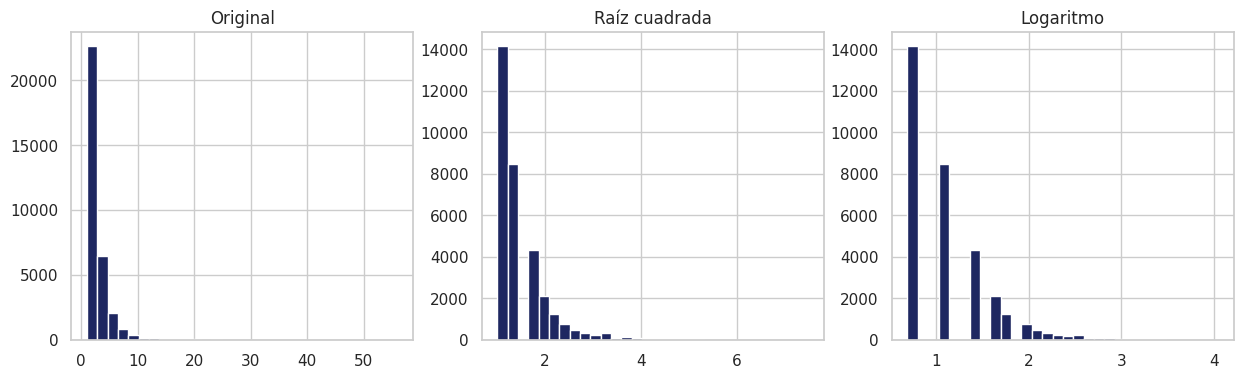

In [12]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

variables = ["age", "duration", "campaign"]

tabla = pd.DataFrame({
    "original": ent[variables].skew(),
    "raiz_cuadrada": np.sqrt(ent[variables]).skew(),
    "logaritmo": np.log1p(ent[variables]).skew(),
}).round(2)
print(tabla)

variable = "campaign"

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(ent[variable].dropna(), bins=30, color=AZUL, edgecolor="white")
ejes[0].set_title("Original")
ejes[1].hist(np.sqrt(ent[variable]).dropna(), bins=30, color=AZUL, edgecolor="white")
ejes[1].set_title("Raíz cuadrada")
ejes[2].hist(np.log1p(ent[variable]).dropna(), bins=30, color=AZUL, edgecolor="white")
ejes[2].set_title("Logaritmo")
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Observación: La predicción fue correcta ya que el logaritmo redujo más la asimetría de campaign (de 4.74 a 1.35) que la raíz cuadrada (2.16). Como la variable tiene una cola muy larga, necesitaba una transformación fuerte. Aun así se observa asimetría porque la mayoría de los clientes sigue concentrada en pocos contactos.**



## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Mi predicción es que job sea una de las variables, ya que si contratas un producto así es porque se tienen los recursos para invertirlos, y poutcome ya que si contratas un producto bancario es probable que lo contrates nuevamente. Por el contrario, no veo a marital, contacto o month separando clases ya que no hay mucha relación para la contratación)**


In [13]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.

categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]

print("Número de categorías por característica:")
print(ent[categoricas].nunique().sort_values())
print()
print("Tasa de contratacion global:", round(ent["suscribe"].mean() * 100, 1), "%")

Número de categorías por característica:
contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12
dtype: int64

Tasa de contratacion global: 11.3 %


In [14]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.


largo = ent[categoricas].astype(str).assign(suscribe=ent["suscribe"]).melt(
    id_vars="suscribe", var_name="caracteristica", value_name="categoria"
)
tasas = largo.groupby(["caracteristica","categoria"])["suscribe"].agg(clientes="count", tasa_contratacion="mean")
tasas["tasa_contratacion"] = (tasas["tasa_contratacion"] * 100).round(1)

print("Categorías con mayor tasa de contratacion:")
print(tasas.sort_values("tasa_contratacion", ascending=False).head(12))
print()
print("Categorías con menor tasa de contratacion:")
print(tasas.sort_values("tasa_contratacion", ascending=False).tail(8))
print()
print("Tabla de default:")
print(pd.crosstab(ent["default"], ent["suscribe"]))
print()
print("Tabla de loan:")
print(pd.crosstab(ent["loan"], ent["suscribe"]))
print()
print("Tabla de housing:")
print(pd.crosstab(ent["housing"], ent["suscribe"]))
print()
print("Tabla de day_of_week:")
print(pd.crosstab(ent["day_of_week"], ent["suscribe"]))
print()

Categorías con mayor tasa de contratacion:
                           clientes  tasa_contratacion
caracteristica categoria                              
poutcome       success         1105               64.9
month          dec              143               50.3
               mar              436               49.8
               sep              464               44.6
               oct              587               43.3
job            student          711               30.5
               retired         1366               25.5
month          apr             2085               20.5
education      illiterate        16               18.8
marital        unknown           65               16.9
education      unknown         1397               14.8
contact        cellular       20908               14.7

Categorías con menor tasa de contratacion:
                            clientes  tasa_contratacion
caracteristica categoria                               
education      basic.6y        

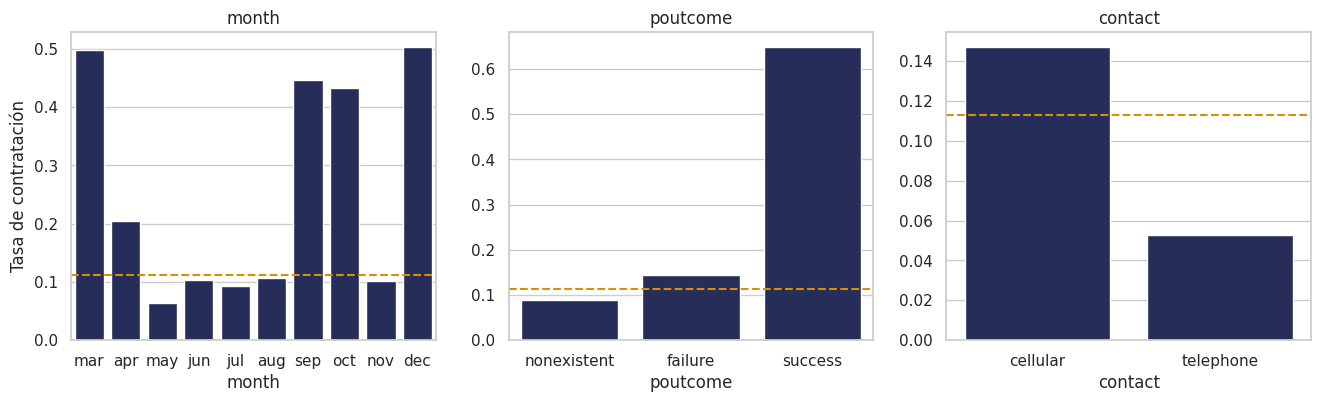

In [15]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.


orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
tasa_global = ent["suscribe"].mean()

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=ent, x="month", y="suscribe", order=orden_meses, color="#1E2761", errorbar=None, ax=ejes[0])
sns.barplot(data=ent, x="poutcome", y="suscribe", color="#1E2761", errorbar=None, ax=ejes[1])
sns.barplot(data=ent, x="contact", y="suscribe", color="#1E2761", errorbar=None, ax=ejes[2])

for eje in ejes:
    eje.axhline(tasa_global, color="#D98E04", linestyle="--")

ejes[0].set_ylabel("Tasa de contratación")
ejes[1].set_ylabel("")
ejes[2].set_ylabel("")
ejes[0].set_title("month")
ejes[1].set_title("poutcome")
ejes[2].set_title("contact")
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

**Observación: la categoría con mayor tasa son efectivamente poutcome lo cual coincide con mi predicción, sin embargo algo qe no esperaba es month, la cual tiene tambien una tasa alta y se observa que diciembre y marzo son los que destacan, podría deberse (mi propia personal hipótesis) que tras recibir bonos laborales o el bono navideño, se busca invertir ese dinero. Otra predicción acertada a medias fue job, aunque para mi sorpresa, student y retired fueron las tasas más altas ya que yo esperaba que la población laboralmente activa fueran las que se interesaran en ese producto. Por otro lado, default - unknown quedó como uno de los que no separan las clases, contacto por telefono, més de mayo y trabajo blue-collar**

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

**Respuesta.En default, unknown contrata el 5.2 % (6,940 clientes), frente al 12.9 % de no (26,007 clientes). Que la tasa sea tan distinta indica que unknown debe tener algún significado asociado posiblemente con menor contratación, así que tiene importancia y conviene conservarla como categoría propia.
Poro otro lado con default = yes hay solo 3 clientes (0 contrataciones) y con education = illiterate solo 16 (tasa de 18.8 %, es decir, 3 clientes). Con tan pocos registros, esas tasas no son confiables y no sería exacto sacar conclusiones de ellas**

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Mi predicción es que los pares más correlacionados sean euribor3m con emp.var.rate y con nr.employed, porque generalmente cuando hay aumento o disminución de empleo, los bancos mueven tasas de intereses y también emp.var.rate con nr.employed ya que ambos son indicadores de empleo**

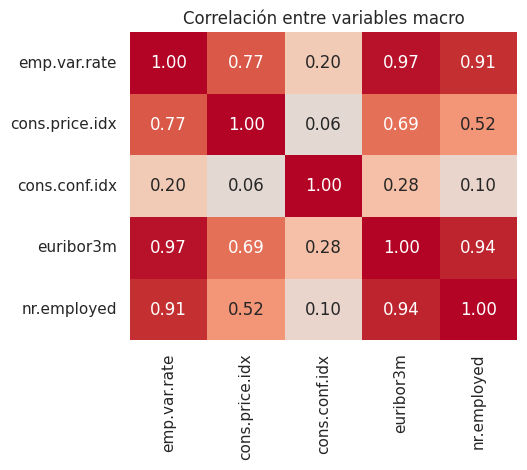

In [16]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(ent[macro].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Correlación entre variables macro")
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

**Efectivamente los más correlacionados fueron emp.var.rate y euribor3m, nr.employed con euribor3m y nr.employed con emp.var.rate. Con lo anterior, yo conservaría euribor3m y emp.var.rate para mi modelo**

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [17]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

print(ent.groupby("y")["duration"].describe())

       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

No, ya que duration es la duración de la llamada en segundos y solo se conoce cuando la llamada termina. El modelo se usará para decidir a quién llamar, es decir, antes de marcar, así que en ese momento el dato no existe.
Con lo observado, la mediana fue 164 en no y 448 en yes, la diferencia más marcada de toda la tabla. Separa tan bien porque como ya dijimos está determinada por el resultado y no porque sea causal.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores
económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte
C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

**Respuesta: Implica que el modelo entrenaría con contactos de fechas posteriores a algunos que luego se usan para probarlo, es decir, "vería el futuro" durante el entrenamiento. Por otro lado, como todos los clientes de un mismo periodo comparten los mismos indicadores económicos, el modelo podría apoyarse en ellos para reconocer el periodo en lugar de aprender algo del cliente, y en la prueba encontraría periodos que ya conoce. Por eso la evaluación saldría más optimista de lo real ya que una campaña futura ocurrirá en un contexto económico nuevo.**

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| duration solo se conoce al terminar la llamada. Mediana de 164 en no frente a 448 en yes, la mayor diferencia de la tabla. Además hay 4 llamadas con duration igual a 0. | Excluir duration de las características, porque el modelo decide a quién llamar antes de marcar. | Preprocesamiento (selección de características) |
| default tiene 8,597 unknown en el total (20.87 %). En entrenamiento, su tasa de contratación es de 5.2 % frente a 11.3 % global. Otras columnas con unknown: education 1,731, housing y loan 990 cada una, job 330, marital 80. | Conservar unknown como categoría propia (no imputar ni eliminar filas), porque tiene señal y no se documenta su causa. | Preprocesamiento |
| pdays vale 999 en 39,673 filas (96.32 %); es un código de "no contactado antes", no una cantidad. Ocurre en las 35,563 filas con poutcome igual a nonexistent. | Crear una variable binaria "contactado antes" y usar pdays solo en quienes sí lo fueron. No escalar ni transformar el 999. | Preprocesamiento |
| contrata el 11.3 % (3,712 de 32,950). Razón entre clases de 7.88. Responder siempre no acierta el 88.7 %. | no usar la exactitud sola | Preprocesamiento y evaluación |
| Redundancia: euribor3m, emp.var.rate y nr.employed correlacionan entre 0.91 y 0.97. cons.conf.idx es casi independiente (máximo 0.28). | se puede conservar una sola del bloque (por ejemplo euribor3m) más cons.conf.idx | Preprocesamiento y modelos |
| Asimetría en campaign ya que hay 4.74 original, 2.16 con raíz cuadrada y 1.35 con logaritmo. Hay 1,916 registros fuera de los límites de Tukey (máximo de 56 contactos). | No eliminar atípicos (son valores reales). Aplicar np.log1p a campaign | Preprocesamiento |
| previous tiene 4,534 registros fuera de Tukey porque casi todos valen 0, y age tiene 368 (máximo de 98 años). | Conservar ambos contactar antes y la edad avanzada son datos reales y posiblemente informativos.

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

****Respuesta.** Con el conjunto total df se hicieron la parte B (descripción de los datos y detección de problemas de calidad): dimensiones, tipos, valores únicos, unknown, duplicados, el código 999 de pdays y los rangos según el dominio. Estas verificaciones son estructurales o del dominio: no usan la variable objetivo ni calculan parámetros que se apliquen al modelo.
Solo con entrenamiento (ent) se hicieron las partes D, E y F: la distribución del objetivo, las medianas por clase, los límites de Tukey, la asimetría, las tasas de contratación por categoría, la matriz de correlación y el resumen de duration. Todas relacionan características con el objetivo o calculan valores a partir de los datos, y eso equivale a seleccionar características o estimar parámetros. Si se hicieran con el total, las decisiones incorporarían información del conjunto de prueba.La parte C fue la división (80 % y 20 %, estratificada,random_state=42), y a partir de ahí prueba no se usó en ninguna celda.**




**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

****Respuesta.** Podría quedar sesgada la decisión sobre qué variables conservar o descartar, por ejemplo mantener poutcome, month y job, o descartar day_of_week. Esas decisiones se apoyan en las tasas de contratación por categoría, y si esas tasas se hubieran calculado con datos de prueba, la selección se habría ajustado también a esos registros. Lo mismo aplica a los límites de Tukey y a la elección de la transformación de campaign, que dependen de los cuartiles y de la asimetría. En la evaluación final, el modelo se vería mejor de lo que realmente es y todo sería muy optimista, porque la prueba ya habría influido en cómo se prepararon los datos. Al usarlo con clientes nuevos, el desempeño real sería menor que el reportado.**